# Modus Ponens Generalizado

El modus ponens clásico dice: «si A entonces B; A es cierto; luego B es cierto». El **generalizado**
admite que el hecho no coincida exactamente con el antecedente: «si X es A entonces Y es B; X es A′;
luego Y es B′». El resultado ya no es un valor, es un **conjunto borroso**.

Este anexo reproduce el cálculo de la implementación en FuzzyCLIPS: una sola regla, la implicación de Kleene-Dienes
y una composición max-min.

- **T-norma mínimo**: `T(a, b) = min(a, b)`
- **T-conorma máximo**: `S(a, b) = max(a, b)`
- **Implicación de Kleene-Dienes**: `I(a, b) = max(1 − a, b)`
- **Composición max-min** entre el hecho y la relación de la regla.

La regla es «si la mucosa es rosada y la condición es flaca, entonces desparasitar». El hecho es la
oveja KT001-26: mucosa blanca y condición normal.


In [1]:
import numpy as np
import pandas as pd

mucosa = {"rojo": 0.1, "rosado": 0.5, "blanco": 1.0}
condicion = {"gordo": 0.2, "normal": 0.6, "flaca": 1.0}
salida = {"desparasitar": 1.0, "a criterio": 0.5, "no desparasitar": 0.1}

combinaciones = [(m, c) for m in mucosa for c in condicion]

R = []
for m, c in combinaciones:
    antecedente = min(mucosa[m], condicion[c])          # t-norma mínimo
    R.append([max(1 - antecedente, b) for b in salida.values()])  # Kleene-Dienes
R = np.array(R)

tabla = pd.DataFrame(
    R,
    index=[f"{m} / {c}" for m, c in combinaciones],
    columns=list(salida),
)
print("Relación de la regla R:")
display(tabla.round(3))

# Hecho KT001-26: blanco / normal, con grado 0.6
h = np.zeros(len(combinaciones))
h[combinaciones.index(("blanco", "normal"))] = 0.6

resultado = np.max(np.minimum(h[:, None], R), axis=0)  # composición max-min
print("Resultado (desparasitar, a criterio, no desparasitar):", resultado.round(3))


Relación de la regla R:


,desparasitar,a criterio,no desparasitar
rojo / gordo,1.0,0.9,0.9
rojo / normal,1.0,0.9,0.9
rojo / flaca,1.0,0.9,0.9
rosado / gordo,1.0,0.8,0.8
rosado / normal,1.0,0.5,0.5
rosado / flaca,1.0,0.5,0.5
blanco / gordo,1.0,0.8,0.8
blanco / normal,1.0,0.5,0.4
blanco / flaca,1.0,0.5,0.1


Resultado (desparasitar, a criterio, no desparasitar): [0.6 0.5 0.4]


### Cálculo original

Recortes del cálculo a mano. Arriba, la tabla de la regla con la matriz de implicación y el vector
del hecho; abajo, la composición max-min y el conjunto de salida.

![Regla, implicación y hecho](images/regla-y-matriz.jpg)

![Composición max-min y salida](images/composicion.jpg)


El vector del hecho solo tiene un valor distinto de cero, `0.6`, en la fila (blanco, normal). Esa
fila de la relación vale `[1.0, 0.5, 0.4]`. El mínimo con 0.6 deja `[0.6, 0.5, 0.4]`: la condición
normal atenúa la recomendación de desparasitar, pero sigue siendo la más alta de las tres.

La diferencia con el sistema Mamdani del notebook principal:

| | Modus Ponens Generalizado | Mamdani |
|---|---|---|
| Reglas | una | cinco |
| Implicación | Kleene-Dienes | mínimo |
| Agregación | — | máximo |
| Salida | conjunto borroso | valor desfuzzificado |

El GMP sirve para razonar sobre conjuntos; Mamdani sirve para tomar una decisión concreta.


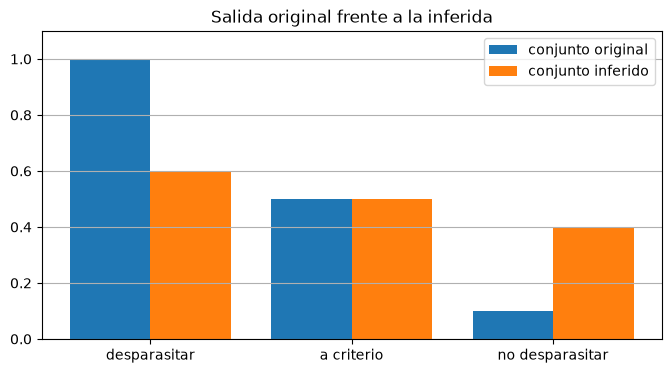

In [2]:
import matplotlib.pyplot as plt

x = np.arange(len(salida))
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, list(salida.values()), width=0.4, label="conjunto original")
plt.bar(x + 0.2, resultado, width=0.4, label="conjunto inferido")
plt.xticks(x, list(salida))
plt.ylim(0, 1.1)
plt.title("Salida original frente a la inferida")
plt.grid(axis="y")
plt.legend()
plt.show()
